=== SPESIFIKASI DAN MODEL DATA ===
Mobil: Ferrari 458 Speciale V8
Persamaan Laju Bensin: v(t) = 0.0003*t^2 + 0.004*t + 0.035
Durasi Perjalanan: 0 sampai 30 menit

=== HASIL PERHITUNGAN ANALITIK ===
Total bensin yang habis (Analitik): 5.5500 Liter

=== HASIL PERHITUNGAN NUMERIK ===
Hasil Metode Trapesium (n = 1.000)   : 5.5500 Liter
Hasil Metode Trapesium (n = 100.000) : 5.5500 Liter

=== VALIDASI DAN ANALISIS ERROR ===
Pada n = 1.000   -> Error Absolut: 0.000001 | Error Relatif: 0.0000%
Pada n = 100.000 -> Error Absolut: 0.000000 | Error Relatif: 0.0000%
Kesimpulan: Semakin banyak jumlah trapesium (n), hasil numerik semakin mendekati hasil analitik.



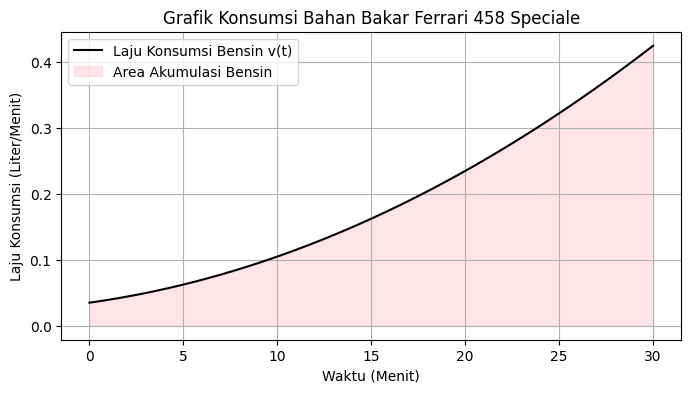

In [1]:
import matplotlib.pyplot as plt

# --- LANGKAH 1: MENENTUKAN PARAMETER DATA ---
# Batas waktu perjalanan (0 sampai 30 menit)
batas_bawah = 0
batas_atas = 30

# Konstanta fungsi laju bensin: v(t) = 0.0003*t^2 + 0.004*t + 0.035
a = 0.0003
b = 0.004
c = 0.035

print("=== SPESIFIKASI DAN MODEL DATA ===")
print("Mobil: Ferrari 458 Speciale V8")
print("Persamaan Laju Bensin: v(t) = 0.0003*t^2 + 0.004*t + 0.035")
print(f"Durasi Perjalanan: {batas_bawah} sampai {batas_atas} menit\n")


# --- LANGKAH 2: SOLUSI ANALITIK / MANUAL ---
# Kita tahu hasil integral dari (a*t^2 + b*t + c) adalah:
# s(t) = (a/3)*t^3 + (b/2)*t^2 + c*t
# Mari kita hitung langsung menggunakan rumus matematika di Python

# Rumus integral di batas atas (t = 30)
hasil_batas_atas = (a / 3) * (batas_atas ** 3) + (b / 2) * (batas_atas ** 2) + c * batas_atas

# Rumus integral di batas bawah (t = 0)
hasil_batas_bawah = (a / 3) * (batas_bawah ** 3) + (b / 2) * (batas_bawah ** 2) + c * batas_bawah

# Hasil akhir analitik (F(30) - F(0))
bensin_analitik = hasil_batas_atas - hasil_batas_bawah

print("=== HASIL PERHITUNGAN ANALITIK ===")
print(f"Total bensin yang habis (Analitik): {bensin_analitik:.4f} Liter\n")


# --- LANGKAH 3: SOLUSI NUMERIK METODE TRAPESIUM ---
# Di sini kita tidak memakai library rumus jadi. Kita buat hitungan trapesium manual
# agar sangat mudah dijelaskan alur algoritmanya.

def hitung_trapesium_manual(n):
    # Lebar setiap potongan trapesium (lebar = (b - a) / n)
    lebar = (batas_atas - batas_bawah) / n
    
    # Hitung tinggi ujung kiri dan ujung kanan terlebih dahulu
    tinggi_awal = a * (batas_bawah ** 2) + b * batas_bawah + c
    tinggi_akhir = a * (batas_atas ** 2) + b * batas_atas + c
    
    # Jumlahkan tinggi awal dan tinggi akhir
    jumlah_tinggi = tinggi_awal + tinggi_akhir
    
    # Perulangan untuk menjumlahkan tinggi trapesium di bagian tengah
    for i in range(1, n):
        # Cari titik t ke-i
        t_sekarang = batas_bawah + i * lebar
        # Hitung tinggi v(t) pada titik tersebut
        tinggi_sekarang = a * (t_sekarang ** 2) + b * t_sekarang + c
        # Dalam rumus trapesium, tinggi bagian tengah dikalikan 2
        jumlah_tinggi = jumlah_tinggi + 2 * tinggi_sekarang
        
    # Rumus Luas Trapesium Total = (lebar / 2) * Jumlah Semua Tinggi
    luas_total = (lebar / 2) * jumlah_tinggi
    return luas_total

# Sesuai tugas, kita hitung untuk n = 1.000 dan n = 100.000
bensin_numerik_kecil = hitung_trapesium_manual(1000)
bensin_numerik_besar = hitung_trapesium_manual(100000)

print("=== HASIL PERHITUNGAN NUMERIK ===")
print(f"Hasil Metode Trapesium (n = 1.000)   : {bensin_numerik_kecil:.4f} Liter")
print(f"Hasil Metode Trapesium (n = 100.000) : {bensin_numerik_besar:.4f} Liter\n")


# --- LANGKAH 4: VALIDASI ERROR ---
# Menghitung selisih hasil antara analitik dan numerik
error_absolut_kecil = abs(bensin_analitik - bensin_numerik_kecil)
error_relatif_kecil = (error_absolut_kecil / bensin_analitik) * 100

error_absolut_besar = abs(bensin_analitik - bensin_numerik_besar)
error_relatif_besar = (error_absolut_besar / bensin_analitik) * 100

print("=== VALIDASI DAN ANALISIS ERROR ===")
print(f"Pada n = 1.000   -> Error Absolut: {error_absolut_kecil:.6f} | Error Relatif: {error_relatif_kecil:.4f}%")
print(f"Pada n = 100.000 -> Error Absolut: {error_absolut_besar:.6f} | Error Relatif: {error_relatif_besar:.4f}%")
print("Kesimpulan: Semakin banyak jumlah trapesium (n), hasil numerik semakin mendekati hasil analitik.\n")


# --- LANGKAH 5: GRAFIK MATPLOTLIB SEDERHANA ---
# Membuat data koordinat titik untuk digambar menjadi grafik garis
titik_waktu = []
titik_laju = []

# Kita buat 100 titik data dari waktu 0 sampai 30 menit menggunakan loop biasa
jumlah_titik_plot = 100
lebar_plot = (batas_atas - batas_bawah) / jumlah_titik_plot

for i in range(jumlah_titik_plot + 1):
    waktu_skr = batas_bawah + i * lebar_plot
    laju_skr = a * (waktu_skr ** 2) + b * waktu_skr + c
    
    # Masukkan nilai ke dalam list
    titik_waktu.append(waktu_skr)
    titik_laju.append(laju_skr)

# Mulai menggambar grafik
plt.figure(figsize=(8, 4))

# Gambar kurva laju bensin warna merah
plt.plot(titik_waktu, titik_laju, color='black', label='Laju Konsumsi Bensin v(t)')

# Arsir area di bawah grafik untuk melambangkan bensin yang habis
plt.fill_between(titik_waktu, titik_laju, color='pink', alpha=0.4, label='Area Akumulasi Bensin')

# Tambahkan dekorasi teks sederhana
plt.xlabel('Waktu (Menit)')
plt.ylabel('Laju Konsumsi (Liter/Menit)')
plt.title('Grafik Konsumsi Bahan Bakar Ferrari 458 Speciale')
plt.grid(True)
plt.legend()

# Tampilkan grafik
plt.show()